# Análisis de las heladas en la estación J2 El Mantaro

Estación **J2 El Mantaro** (valle del Mantaro, Junín; 3.314 m). Datos horarios de 2022-03 a 2026-10.

**Contenido**

1. Datos y cobertura por temporada
2. Definiciones e inventario de noches de helada
3. Estacionalidad: en qué meses y semanas hiela
4. Temporada de heladas: primera y última helada, periodo libre de heladas
5. Variabilidad entre años
6. Evolución dentro de la noche: inicio, hora del mínimo, duración y enfriamiento
7. Condiciones meteorológicas asociadas: tarde previa, viento, humedad, nubosidad
8. Rachas de noches consecutivas con helada
9. Tipo de helada (blanca/negra) según el sensor de humedad de hoja
10. Heladas blancas y negras y su relación con la humedad del aire
11. Temperatura del suelo durante las heladas
12. Riesgo agronómico: umbrales críticos e intensidad acumulada
13. Resumen

**Convenciones**

* Una **noche** va de las 18:00 del día D a las 08:00 del día D+1 y se etiqueta con la fecha D.
* Variable principal: `temperatura_minima` horaria del abrigo meteorológico (~2 m).
* **Helada meteorológica**: Tmin ≤ 0 °C. **Helada agronómica**: Tmin ≤ 2 °C (con cielo despejado el cultivo está entre 2 y 3 °C más frío que el aire a 2 m).
* **Noche válida**: al menos 12 de sus 15 horas tienen dato.

> El registro abarca solo **4–5 temporadas**. Las estadísticas describen *este periodo* y no son una climatología de largo plazo. Las probabilidades y fechas deben leerse como orientativas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
EXT = BASE / 'data' / 'external'
OUT = BASE / 'resultados'; OUT.mkdir(exist_ok=True)

EST = 'j2_el_mantaro'
T_HELADA, T_AGRO = 0.0, 2.0
UMB_CRITICOS = [0, -2, -4]           # °C, umbrales de daño orientativos (papa/haba/maíz: ~ -2 °C)
UMB_HIELO = 10                       # señal de hoja (rel. a base seca) para considerar que hubo escarcha
MESES = ['E', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']
MESES_L = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']
COL = {'suave': '#9ecae1', 'moderada': '#4292c6', 'fuerte': '#08306b', 'blanca': '#6baed6', 'negra': '#252525'}

## 1. Datos y cobertura

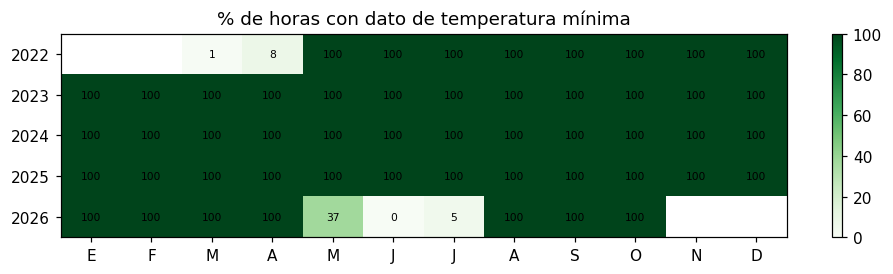

Cobertura abr–oct por año (%): {2022: 87.0, 2023: 100.0, 2024: 100.0, 2025: 100.0, 2026: 62.0}
Temporadas completas: [2023, 2024, 2025]


In [2]:
REN = {'temperatura_media': 'T', 'temperatura_minima': 'Tmin', 'temperatura_maxima': 'Tmax',
       'punto_rocio_medio': 'Td', 'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
       'precipitacion_acc_1h': 'pp', 'radiacion_solar_media_1h': 'rad',
       'rh_hoja_arriba_media_1h': 'arriba', 'rh_hoja_bajo_media_1h': 'bajo',
       'suelo_temperatura_5cm': 'Tsuelo5', 'suelo_temperatura_15cm': 'Tsuelo15'}
raw = pd.read_csv(DATA / 'horario' / f'{EST}.csv', parse_dates=['fecha']).set_index('fecha')
D = raw.rename(columns=REN)[list(REN.values())].asfreq('h')
D['dep'] = D['T'] - D['Td']
D['noche'] = (D.index - pd.Timedelta(hours=12)).normalize()
D['es_noche'] = (D.index.hour >= 18) | (D.index.hour <= 8)

nub_f = EXT / 'openmeteo_nubosidad_j2_el_mantaro.csv'
NUB = pd.read_csv(nub_f, parse_dates=['fecha']).set_index('fecha') if nub_f.exists() else None
if NUB is not None:
    D = D.join(NUB)

cob = D['Tmin'].notna().groupby([D.index.year, D.index.month]).mean().unstack() * 100
fig, ax = plt.subplots(figsize=(9, 2.6))
im = ax.imshow(cob.values, cmap='Greens', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(12), MESES); ax.set_yticks(range(len(cob)), cob.index); ax.grid(False)
for i in range(cob.shape[0]):
    for j in range(cob.shape[1]):
        v = cob.values[i, j]
        if not np.isnan(v): ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7)
ax.set_title('% de horas con dato de temperatura mínima'); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

# temporada completa: abril-octubre con >= 90 % de horas con dato
temp_cob = D.loc[D.index.month.isin(range(4, 11)), 'Tmin'].notna().groupby(D.index[D.index.month.isin(range(4, 11))].year).mean()
COMPLETAS = list(temp_cob[temp_cob >= 0.9].index)
print('Cobertura abr–oct por año (%):', (temp_cob * 100).round(0).to_dict())
print('Temporadas completas:', COMPLETAS)

## 2. Inventario de noches de helada

In [3]:
n = D[D['es_noche']]
g = n.groupby('noche')

def hora_rel(ts, noche):
    # horas desde las 18:00 de la noche
    return (ts - (noche + pd.Timedelta(hours=18))) / pd.Timedelta(hours=1)

N = pd.DataFrame({
    'horas_dato': g['Tmin'].count(),
    'tmin': g['Tmin'].min(),
    'horas_bajo0': g['Tmin'].apply(lambda s: (s <= 0).sum()),
    'horas_bajo2': g['Tmin'].apply(lambda s: (s <= 2).sum()),
    'horas_bajo_m2': g['Tmin'].apply(lambda s: (s <= -2).sum()),
    'grados_hora_bajo0': g['Tmin'].apply(lambda s: (-s.clip(upper=0)).sum()),   # intensidad acumulada (°C·h)
    'viento': g['viento'].mean(),
    'hr_max': g['HR'].max(),
    'pp_noche': g['pp'].sum(min_count=1),
})
N = N[N['horas_dato'] >= 12].copy()
im = n.dropna(subset=['Tmin']).groupby('noche')['Tmin'].idxmin()
N['hora_tmin'] = im.reindex(N.index)
N['h_tmin'] = hora_rel(N['hora_tmin'], N.index.to_series())
N['td_tmin'] = D['Td'].reindex(N['hora_tmin']).values
N['dep_tmin'] = D['dep'].reindex(N['hora_tmin']).values
# condiciones de la tarde previa (18 h) y máxima del día
for c in ('T', 'Td', 'HR', 'dep'):
    N[f'{c}_18h'] = D[c].reindex(N.index + pd.Timedelta(hours=18)).values
N['tmax_dia'] = D['Tmax'].groupby(D.index.normalize()).max().reindex(N.index).values
N['amplitud'] = N['tmax_dia'] - N['tmin']
if NUB is not None:
    N['nubosidad'] = g['cloud_cover'].mean().reindex(N.index)
    N['nubosidad_baja'] = g['cloud_cover_low'].mean().reindex(N.index)

N['helada'] = N['tmin'] <= T_HELADA
N['helada_agro'] = N['tmin'] <= T_AGRO
N['intensidad'] = pd.cut(N['tmin'], [-np.inf, -4, -2, T_HELADA], labels=['fuerte', 'moderada', 'suave'])
N['anio'], N['mes'] = N.index.year, N.index.month
N['completa'] = N['anio'].isin(COMPLETAS)

H = N[N['helada']]
print(f"Noches válidas: {len(N)} | heladas (≤0 °C): {len(H)} | agronómicas (≤2 °C): {N['helada_agro'].sum()}")
print(f"Tmin absoluta: {N['tmin'].min():.1f} °C el {N['tmin'].idxmin():%Y-%m-%d}")
H['intensidad'].value_counts().reindex(['suave', 'moderada', 'fuerte']).to_frame('noches')

Noches válidas: 1560 | heladas (≤0 °C): 268 | agronómicas (≤2 °C): 467
Tmin absoluta: -6.8 °C el 2025-07-05


,noches
intensidad,
suave,150
moderada,86
fuerte,32


In [4]:
# Las 15 heladas más intensas
H.nsmallest(15, 'tmin')[['tmin', 'horas_bajo0', 'grados_hora_bajo0', 'hora_tmin', 'T_18h', 'Td_18h', 'viento',
                        *(['nubosidad'] if NUB is not None else [])]].round({'tmin': 1, 'grados_hora_bajo0': 1, 'T_18h': 1, 'Td_18h': 1, 'viento': 1, 'nubosidad': 0})

,tmin,horas_bajo0,grados_hora_bajo0,hora_tmin,T_18h,Td_18h,viento,nubosidad
noche,,,,,,,,
2025-07-05,-6.8,10,41.6,2025-07-06 07:00:00,14.0,-9.1,0.3,0.0
2025-07-04,-6.3,11,43.8,2025-07-05 07:00:00,14.0,-10.2,0.4,15.0
2025-07-06,-5.9,11,41.3,2025-07-07 07:00:00,14.6,-9.2,0.3,0.0
2022-06-30,-5.4,9,31.2,2022-07-01 07:00:00,17.3,-7.1,0.5,20.0
2025-07-07,-5.4,10,35.9,2025-07-08 07:00:00,14.1,-6.1,0.4,14.0
2022-07-01,-5.3,9,27.0,2022-07-02 07:00:00,16.0,-4.2,0.5,23.0
2023-06-02,-5.2,10,32.4,2023-06-03 07:00:00,13.2,-4.0,0.2,12.0
2024-06-07,-5.2,9,27.7,2024-06-08 07:00:00,15.8,-5.2,0.3,6.0
2022-06-15,-5.1,9,24.7,2022-06-16 07:00:00,14.3,-6.3,0.3,0.0


## 3. Estacionalidad

Para no confundir la falta de datos con la ausencia de helada, mostramos la **frecuencia relativa**: el porcentaje de noches válidas del mes que tuvieron helada.

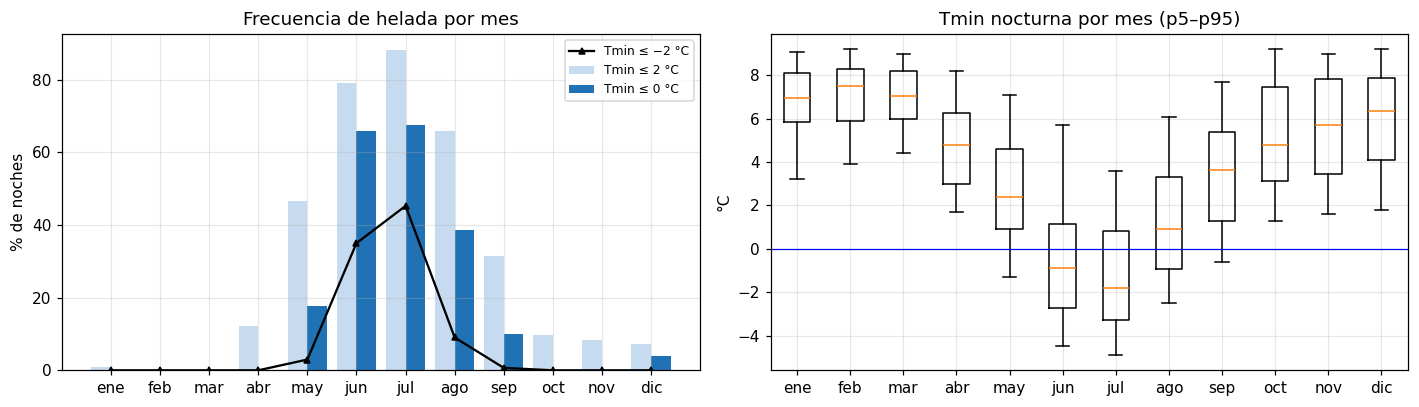

,noches,% ≤0 °C,% ≤2 °C,tmin_media,tmin_abs,% ≤−2 °C,% ≤−4 °C
mes,,,,,,,
ene,124,0.0,0.8,6.7,1.2,0.0,0.0
feb,113,0.0,0.0,7.0,2.3,0.0,0.0
mar,124,0.0,0.0,7.0,2.8,0.0,0.0
abr,123,0.0,12.2,4.7,0.1,0.0,0.0
may,135,17.8,46.7,2.7,-3.8,3.0,0.0
jun,120,65.8,79.2,-0.4,-5.4,35.0,10.8
jul,126,67.5,88.1,-1.2,-6.8,45.2,14.3
ago,155,38.7,65.8,1.2,-4.1,9.0,0.6
sep,150,10.0,31.3,3.5,-3.2,0.7,0.0


In [5]:
mens = N.groupby('mes').agg(noches=('tmin', 'size'), helada=('helada', 'mean'), agro=('helada_agro', 'mean'),
                            tmin_media=('tmin', 'mean'), tmin_abs=('tmin', 'min'))
for u in UMB_CRITICOS[1:]:
    mens[f'p_tmin<={u}'] = N.groupby('mes')['tmin'].apply(lambda s: (s <= u).mean())
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(1, 13)
axs[0].bar(x - .2, mens['agro'].reindex(x) * 100, .4, label='Tmin ≤ 2 °C', color='#c6dbef')
axs[0].bar(x + .2, mens['helada'].reindex(x) * 100, .4, label='Tmin ≤ 0 °C', color='#2171b5')
axs[0].plot(x, mens['p_tmin<=-2'].reindex(x) * 100, 'k^-', ms=4, label='Tmin ≤ −2 °C')
axs[0].set_xticks(x, MESES_L); axs[0].set_ylabel('% de noches'); axs[0].legend(fontsize=8)
axs[0].set_title('Frecuencia de helada por mes')
bp = [N.loc[N.mes == m, 'tmin'].values for m in x]
axs[1].boxplot(bp, tick_labels=MESES_L, whis=(5, 95), showfliers=False)
axs[1].axhline(0, color='b', lw=.8); axs[1].set_ylabel('°C'); axs[1].set_title('Tmin nocturna por mes (p5–p95)')
plt.tight_layout(); plt.show()
(mens.assign(**{c: mens[c] * 100 for c in ['helada', 'agro', 'p_tmin<=-2', 'p_tmin<=-4']})
     .rename(columns={'helada': '% ≤0 °C', 'agro': '% ≤2 °C', 'p_tmin<=-2': '% ≤−2 °C', 'p_tmin<=-4': '% ≤−4 °C'})
     .rename(index=dict(zip(x, MESES_L))).round(1))

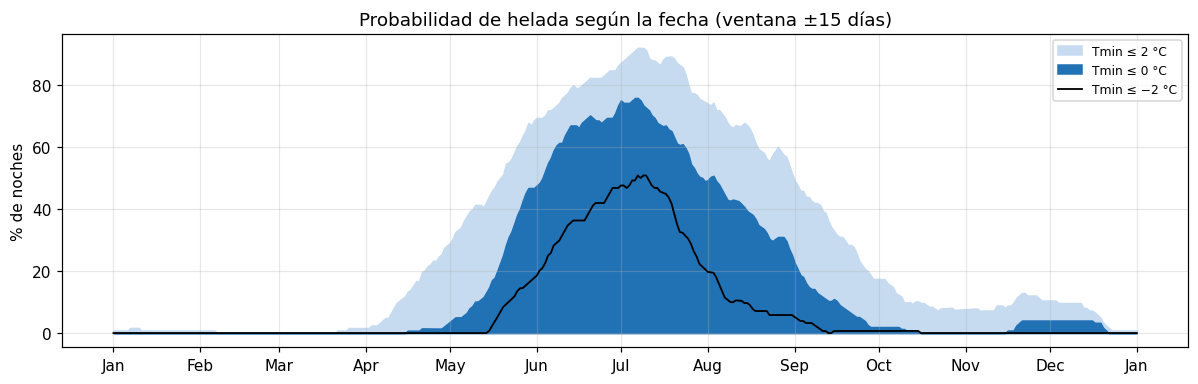

In [6]:
# Probabilidad diaria de helada (ventana móvil de ±15 días, todos los años juntos)
N['doy'] = N.index.dayofyear
def prob_doy(serie_bool, ventana=15):
    out = {}
    for d in range(1, 367):
        dist = np.minimum(np.abs(N['doy'] - d), 366 - np.abs(N['doy'] - d))
        m = dist <= ventana
        out[d] = serie_bool[m].mean() if m.sum() >= 20 else np.nan
    return pd.Series(out)
p0, p2, pm2 = prob_doy(N['helada']), prob_doy(N['helada_agro']), prob_doy(N['tmin'] <= -2)
fechas = pd.to_datetime('2025-01-01') + pd.to_timedelta(p0.index - 1, unit='D')
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(fechas, p2 * 100, color='#c6dbef', label='Tmin ≤ 2 °C')
ax.fill_between(fechas, p0 * 100, color='#2171b5', label='Tmin ≤ 0 °C')
ax.plot(fechas, pm2 * 100, 'k', lw=1.2, label='Tmin ≤ −2 °C')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b')); ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylabel('% de noches'); ax.set_title('Probabilidad de helada según la fecha (ventana ±15 días)')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
PROB_DOY = pd.DataFrame({'fecha': fechas.strftime('%m-%d'), 'p_0C': p0.values, 'p_2C': p2.values, 'p_m2C': pm2.values})
PROB_DOY.to_csv(OUT / 'el_mantaro_probabilidad_helada_diaria.csv', index=False)

## 4. Temporada de heladas

Para cada año con temporada completa: **fecha de la primera y la última helada**, **duración de la temporada** y **periodo libre de heladas** (de la última helada de un año a la primera del siguiente).

In [7]:
def temporada(umbral, col='tmin'):
    filas = []
    for a in sorted(N['anio'].unique()):
        s = N[(N.anio == a) & (N[col] <= umbral)]
        if s.empty: continue
        filas.append({'año': a, 'completa': a in COMPLETAS, 'primera': s.index.min(), 'última': s.index.max(),
                      'duración_días': (s.index.max() - s.index.min()).days + 1, 'noches': len(s)})
    t = pd.DataFrame(filas).set_index('año')
    t['libre_hasta_sig_días'] = (t['primera'].shift(-1) - t['última']).dt.days
    return t

TEMP0, TEMP2 = temporada(T_HELADA), temporada(T_AGRO)
print('Helada meteorológica (≤ 0 °C)'); display(TEMP0)
print('Helada agronómica (≤ 2 °C)'); display(TEMP2)

Helada meteorológica (≤ 0 °C)


,completa,primera,última,duración_días,noches,libre_hasta_sig_días
año,,,,,,
2022,False,2022-05-06,2022-12-04,213,75,148.0
2023,True,2023-05-01,2023-09-09,132,72,256.0
2024,True,2024-05-22,2024-09-22,124,58,253.0
2025,True,2025-06-02,2025-12-06,188,49,236.0
2026,False,2026-07-30,2026-09-30,63,14,NaN


Helada agronómica (≤ 2 °C)


,completa,primera,última,duración_días,noches,libre_hasta_sig_días
año,,,,,,
2022,False,2022-05-01,2022-12-27,241,125,26.0
2023,True,2023-01-22,2023-11-01,284,119,175.0
2024,True,2024-04-24,2024-10-05,165,99,213.0
2025,True,2025-05-06,2025-12-06,215,82,149.0
2026,False,2026-05-04,2026-10-18,168,42,NaN


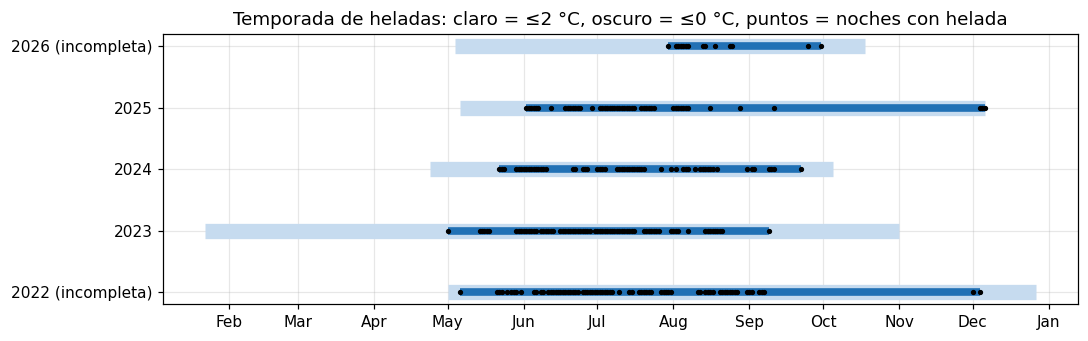

Temporadas completas (≤0 °C): primera helada mediana 23-May (rango 01-May … 02-Jun) | última helada mediana 23-Sep (rango 09-Sep … 06-Dec) | duración mediana 132 días


In [8]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, (a, r) in enumerate(TEMP2.iterrows()):
    p1 = pd.Timestamp(2025, r['primera'].month, r['primera'].day); p2_ = pd.Timestamp(2025, r['última'].month, r['última'].day)
    ax.plot([p1, p2_], [i, i], color='#c6dbef', lw=10, solid_capstyle='butt')
for i, a in enumerate(TEMP2.index):
    if a in TEMP0.index:
        r = TEMP0.loc[a]
        p1 = pd.Timestamp(2025, r['primera'].month, r['primera'].day); p2_ = pd.Timestamp(2025, r['última'].month, r['última'].day)
        ax.plot([p1, p2_], [i, i], color='#2171b5', lw=5, solid_capstyle='butt')
    hs = N[(N.anio == a) & N.helada].index
    ax.scatter([pd.Timestamp(2025, d.month, d.day) for d in hs], [i] * len(hs), s=6, color='k', zorder=3)
ax.set_yticks(range(len(TEMP2)), [f"{a}{'' if a in COMPLETAS else ' (incompleta)'}" for a in TEMP2.index])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b')); ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_title('Temporada de heladas: claro = ≤2 °C, oscuro = ≤0 °C, puntos = noches con helada')
plt.tight_layout(); plt.show()
def fecha_doy(x):
    return pd.to_datetime(int(round(x)) - 1, unit='D', origin='2025-01-01').strftime('%d-%b')
c = TEMP0[TEMP0.completa]
if len(c):
    print('Temporadas completas (≤0 °C): primera helada mediana', fecha_doy(c['primera'].dt.dayofyear.median()),
          f"(rango {fecha_doy(c['primera'].dt.dayofyear.min())} … {fecha_doy(c['primera'].dt.dayofyear.max())})",
          '| última helada mediana', fecha_doy(c['última'].dt.dayofyear.median()),
          f"(rango {fecha_doy(c['última'].dt.dayofyear.min())} … {fecha_doy(c['última'].dt.dayofyear.max())})",
          '| duración mediana', round(c['duración_días'].median()), 'días')

### 4.1 Heladas fuera de temporada ("heladas de verano")

Son heladas entre octubre y abril, en plena temporada de lluvias. Aparecen durante los **veranillos**: días secos, despejados y en calma dentro de la época húmeda. Son pocas y suaves, pero muy dañinas, porque los cultivos están en pleno crecimiento o en floración. Las verificamos hora a hora: el enfriamiento nocturno es coherente y la estación vecina J1 Apata registra 0 °C en las mismas noches, así que no son errores del sensor.

In [9]:
FUERA = N[N['helada'] & ~N['mes'].isin(range(5, 10))]
cols = ['tmin', 'horas_bajo0', 'T_18h', 'Td_18h', 'HR_18h', 'viento', 'pp_noche'] + (['nubosidad'] if NUB is not None else [])
print(f'{len(FUERA)} heladas fuera de mayo–septiembre ({len(FUERA) / N.helada.sum():.1%} del total)')
# lluvia en los 7 días previos (veranillo = varios días secos)
FUERA = FUERA.assign(pp_7d_previos=[D.loc[n_ - pd.Timedelta(days=7): n_ + pd.Timedelta(hours=17), 'pp'].sum() for n_ in FUERA.index])
FUERA[cols + ['pp_7d_previos']].round(1)

5 heladas fuera de mayo–septiembre (1.9% del total)


,tmin,horas_bajo0,T_18h,Td_18h,HR_18h,viento,pp_noche,nubosidad,pp_7d_previos
noche,,,,,,,,,
2022-12-01,-0.2,1,19.6,2.6,33.0,0.6,0.0,25.6,1.2
2022-12-04,-0.4,2,11.8,1.3,48.0,0.3,0.0,61.0,0.8
2025-12-04,-1.0,2,18.9,-1.7,25.0,0.4,0.0,54.5,3.9
2025-12-05,-0.8,3,20.5,-4.8,18.0,0.5,0.0,92.0,1.8
2025-12-06,-1.1,4,19.8,-4.9,19.0,0.4,0.0,79.9,1.6


## 5. Variabilidad entre años

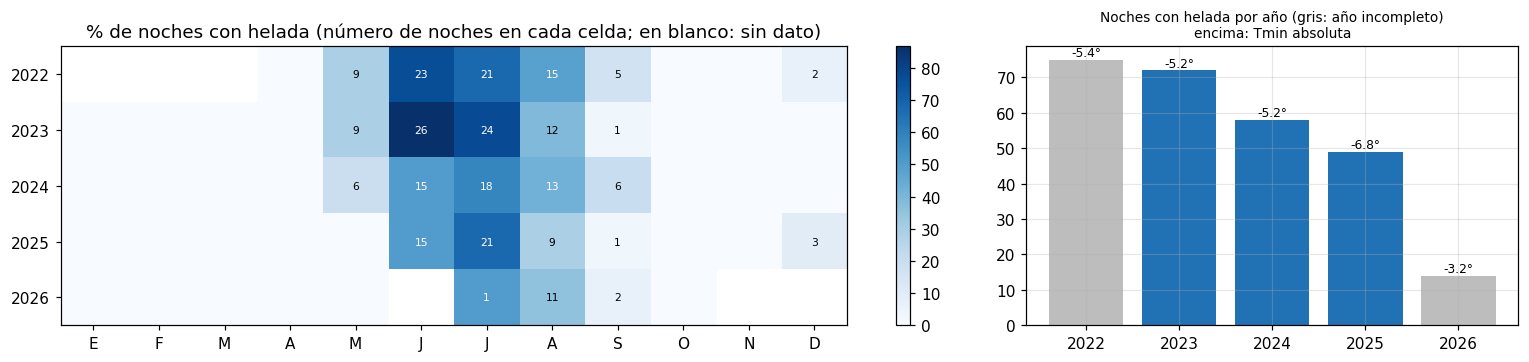

,noches_validas,heladas,agro,fuertes,tmin_abs,horas_bajo0,grados_hora,completa
anio,,,,,,,,
2022,248,75,125,10,-5.4,368,590.3,False
2023,365,72,119,7,-5.2,392,624.1,True
2024,366,58,99,7,-5.2,255,418.7,True
2025,365,49,82,8,-6.8,279,554.7,True
2026,216,14,42,0,-3.2,44,44.3,False


In [10]:
anual = N.groupby('anio').agg(noches_validas=('tmin', 'size'), heladas=('helada', 'sum'), agro=('helada_agro', 'sum'),
                              fuertes=('intensidad', lambda s: (s == 'fuerte').sum()),
                              tmin_abs=('tmin', 'min'), horas_bajo0=('horas_bajo0', 'sum'),
                              grados_hora=('grados_hora_bajo0', 'sum'))
anual['completa'] = anual.index.isin(COMPLETAS)
# heladas por mes y año (frecuencia relativa)
ym = N.pivot_table(index='anio', columns='mes', values='helada', aggfunc='mean').reindex(columns=range(1, 13)) * 100
yn = N.pivot_table(index='anio', columns='mes', values='helada', aggfunc='sum').reindex(columns=range(1, 13))
fig, axs = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={'width_ratios': [2, 1]})
im = axs[0].imshow(ym.values, cmap='Blues', aspect='auto', vmin=0, vmax=np.nanmax(ym.values))
axs[0].set_xticks(range(12), MESES); axs[0].set_yticks(range(len(ym)), ym.index); axs[0].grid(False)
for i in range(ym.shape[0]):
    for j in range(12):
        if not np.isnan(ym.values[i, j]) and yn.values[i, j] > 0:
            axs[0].text(j, i, int(yn.values[i, j]), ha='center', va='center', fontsize=7,
                        color='w' if ym.values[i, j] > 40 else 'k')
axs[0].set_title('% de noches con helada (número de noches en cada celda; en blanco: sin dato)')
plt.colorbar(im, ax=axs[0])
a = anual.reset_index()
axs[1].bar(a['anio'], a['heladas'], color=['#2171b5' if c else '#bdbdbd' for c in a['completa']])
for _, r in a.iterrows():
    axs[1].text(r['anio'], r['heladas'] + 1, f"{r['tmin_abs']:.1f}°", ha='center', fontsize=8)
axs[1].set_title('Noches con helada por año (gris: año incompleto)\nencima: Tmin absoluta', fontsize=9)
plt.tight_layout(); plt.show()
anual.round(1)

## 6. Evolución dentro de la noche

* **Hora de inicio**: primera hora con Tmin ≤ 0 °C. **Hora del mínimo**. **Hora de fin**: última hora bajo 0 °C.
* **Composición de la temperatura** de las noches de helada, separada por intensidad.

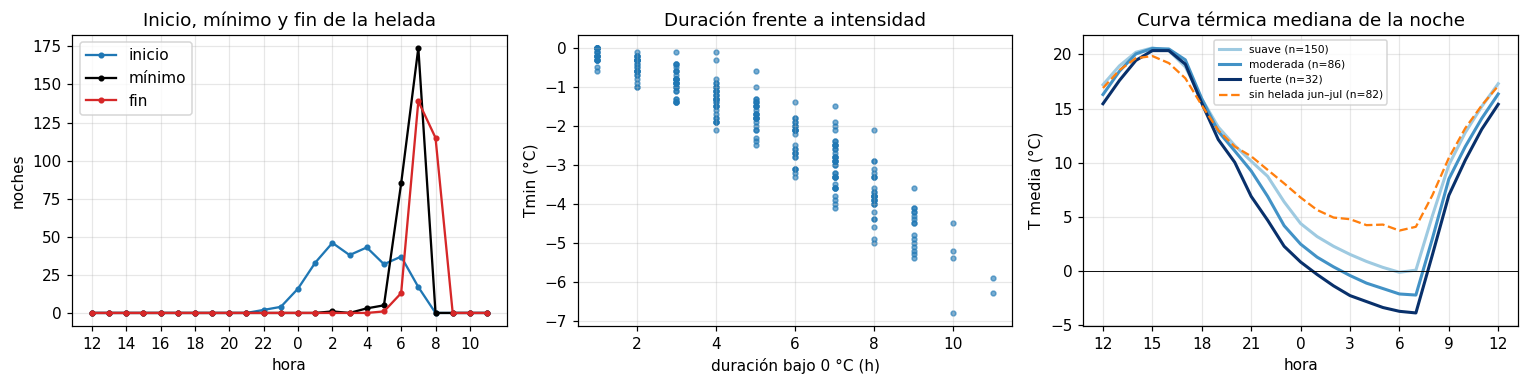

,h_inicio,h_tmin,h_fin,duracion
count,268.0,268.0,268.0,268.0
mean,3.9,6.6,7.4,5.0
std,3.5,0.6,0.6,2.5
min,0.0,2.0,5.0,1.0
25%,2.0,6.0,7.0,3.0
50%,4.0,7.0,7.0,5.0
75%,5.0,7.0,8.0,7.0
max,23.0,7.0,8.0,11.0


In [11]:
filas = []
for noche in H.index:
    s = D.loc[noche + pd.Timedelta(hours=12): noche + pd.Timedelta(hours=36), 'Tmin']
    bajo = s[s <= 0]
    filas.append({'noche': noche, 'inicio': bajo.index.min(), 'fin': bajo.index.max()})
EV = pd.DataFrame(filas).set_index('noche')
EV['h_inicio'] = EV['inicio'].dt.hour; EV['h_fin'] = EV['fin'].dt.hour
EV['h_tmin'] = H['hora_tmin'].dt.hour
EV['duracion'] = (EV['fin'] - EV['inicio']) / pd.Timedelta(hours=1) + 1

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
orden = list(range(12, 24)) + list(range(0, 12))
for col, lab, c in [('h_inicio', 'inicio', 'tab:blue'), ('h_tmin', 'mínimo', 'k'), ('h_fin', 'fin', 'tab:red')]:
    vc = EV[col].value_counts().reindex(orden, fill_value=0)
    axs[0].plot(range(24), vc.values, 'o-', ms=3, color=c, label=lab)
axs[0].set_xticks(range(0, 24, 2), [orden[i] for i in range(0, 24, 2)]); axs[0].set_xlabel('hora')
axs[0].set_ylabel('noches'); axs[0].legend(); axs[0].set_title('Inicio, mínimo y fin de la helada')
axs[1].scatter(EV['duracion'], H['tmin'], s=10, alpha=.6)
axs[1].set_xlabel('duración bajo 0 °C (h)'); axs[1].set_ylabel('Tmin (°C)'); axs[1].set_title('Duración frente a intensidad')
# composición
for intens in ['suave', 'moderada', 'fuerte']:
    idx = H.index[H['intensidad'] == intens]
    M = np.vstack([D['T'].reindex(pd.date_range(nn + pd.Timedelta(hours=12), periods=25, freq='h')).values for nn in idx])
    axs[2].plot(range(12, 37), np.nanmedian(M, axis=0), color=COL[intens], lw=2, label=f'{intens} (n={len(idx)})')
noh = N[~N.helada & N.mes.isin([6, 7])].index
M = np.vstack([D['T'].reindex(pd.date_range(nn + pd.Timedelta(hours=12), periods=25, freq='h')).values for nn in noh])
axs[2].plot(range(12, 37), np.nanmedian(M, axis=0), color='tab:orange', ls='--', label=f'sin helada jun–jul (n={len(noh)})')
axs[2].axhline(0, color='k', lw=.6); axs[2].set_xticks(range(12, 37, 3), [h % 24 for h in range(12, 37, 3)])
axs[2].set_xlabel('hora'); axs[2].set_ylabel('T media (°C)'); axs[2].legend(fontsize=7)
axs[2].set_title('Curva térmica mediana de la noche')
plt.tight_layout(); plt.show()
EV[['h_inicio', 'h_tmin', 'h_fin', 'duracion']].describe().round(1)

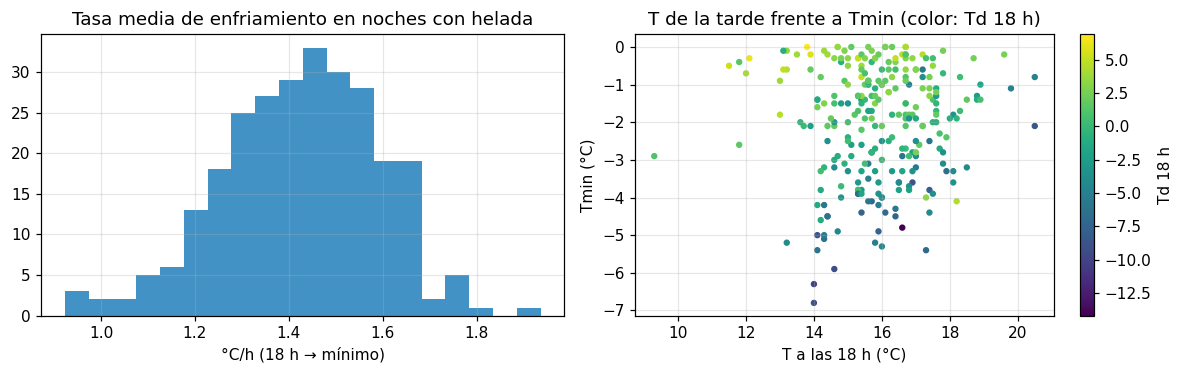

In [12]:
# Velocidad de enfriamiento: de las 18 h a la hora del mínimo
H2 = H.copy()
H2['enfr_tasa'] = (H2['T_18h'] - H2['tmin']) / H2['h_tmin'].clip(lower=1)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].hist(H2['enfr_tasa'].dropna(), bins=20, color='#4292c6'); axs[0].set_xlabel('°C/h (18 h → mínimo)')
axs[0].set_title('Tasa media de enfriamiento en noches con helada')
axs[1].scatter(H2['T_18h'], H2['tmin'], s=10, c=H2['Td_18h'], cmap='viridis')
axs[1].set_xlabel('T a las 18 h (°C)'); axs[1].set_ylabel('Tmin (°C)'); axs[1].set_title('T de la tarde frente a Tmin (color: Td 18 h)')
plt.colorbar(axs[1].collections[0], ax=axs[1], label='Td 18 h'); plt.tight_layout(); plt.show()

## 7. Condiciones meteorológicas asociadas

Comparamos las noches **con** y **sin** helada dentro de la temporada de heladas (mayo–agosto), para que la estación del año no confunda la comparación.

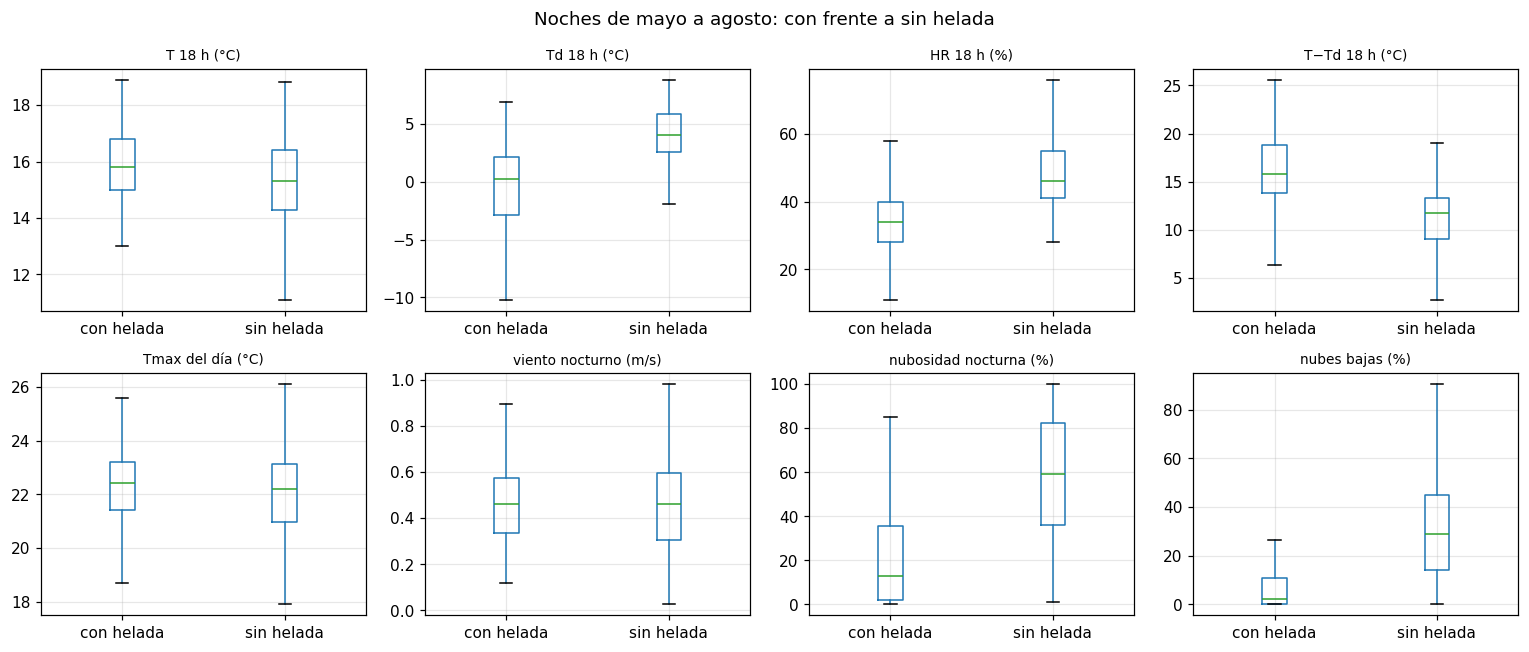

grupo,con helada,sin helada
T_18h,15.8,15.3
Td_18h,0.2,4.0
HR_18h,34.0,46.0
dep_18h,15.8,11.7
tmax_dia,22.4,22.2
viento,0.5,0.5
nubosidad,12.9,59.2
nubosidad_baja,2.2,28.8


In [13]:
temp = N[N.mes.isin([5, 6, 7, 8])].copy()
temp['grupo'] = np.where(temp['helada'], 'con helada', 'sin helada')
vars_ = [('T_18h', 'T 18 h (°C)'), ('Td_18h', 'Td 18 h (°C)'), ('HR_18h', 'HR 18 h (%)'), ('dep_18h', 'T−Td 18 h (°C)'),
         ('tmax_dia', 'Tmax del día (°C)'), ('viento', 'viento nocturno (m/s)')]
if NUB is not None:
    vars_ += [('nubosidad', 'nubosidad nocturna (%)'), ('nubosidad_baja', 'nubes bajas (%)')]
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for ax, (c, lab) in zip(axs.flat, vars_):
    temp.boxplot(column=c, by='grupo', ax=ax, showfliers=False)
    ax.set_title(lab, fontsize=9); ax.set_xlabel('')
plt.suptitle('Noches de mayo a agosto: con frente a sin helada'); plt.tight_layout(); plt.show()
temp.groupby('grupo')[[c for c, _ in vars_]].median().round(1).T

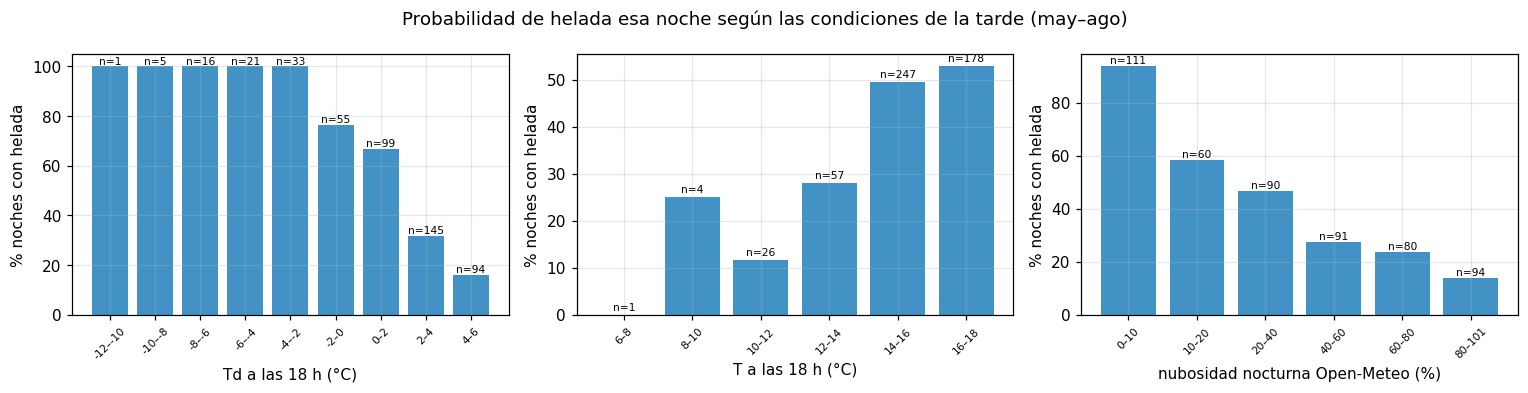

In [14]:
# Probabilidad empírica de helada según las condiciones de la tarde (18 h), mayo–agosto
fig, axs = plt.subplots(1, 3 if NUB is not None else 2, figsize=(14, 3.6))
for ax, (c, bins, lab) in zip(axs, [('Td_18h', np.arange(-12, 8, 2), 'Td a las 18 h (°C)'),
                                    ('T_18h', np.arange(2, 20, 2), 'T a las 18 h (°C)'),
                                    ('nubosidad', [0, 10, 20, 40, 60, 80, 101], 'nubosidad nocturna Open-Meteo (%)')]):
    if c not in temp: continue
    gb = temp.groupby(pd.cut(temp[c], bins), observed=True)['helada'].agg(['mean', 'size'])
    ax.bar(range(len(gb)), gb['mean'] * 100, color='#4292c6')
    for i, (m, nn) in enumerate(gb.values): ax.text(i, m * 100 + 1, f'n={int(nn)}', ha='center', fontsize=7)
    ax.set_xticks(range(len(gb)), [f'{i.left:g}–{i.right:g}' for i in gb.index], rotation=45, fontsize=7)
    ax.set_xlabel(lab); ax.set_ylabel('% noches con helada')
plt.suptitle('Probabilidad de helada esa noche según las condiciones de la tarde (may–ago)')
plt.tight_layout(); plt.show()

In [15]:
# Tabla de doble entrada: T 18 h × Td 18 h (may–ago)
BT, BTD = [0, 12, 14, 16, 18, 30], [-20, -6, -3, 0, 3, 15]
tab = temp.pivot_table(index=pd.cut(temp['T_18h'], BT), columns=pd.cut(temp['Td_18h'], BTD),
                       values='helada', aggfunc='mean', observed=False) * 100
cnt = temp.pivot_table(index=pd.cut(temp['T_18h'], BT), columns=pd.cut(temp['Td_18h'], BTD),
                       values='helada', aggfunc='size', observed=False)
print('% de noches con helada (filas: T 18 h, columnas: Td 18 h); celdas con n < 5 en blanco')
tab.where(cnt >= 5).round(0)

% de noches con helada (filas: T 18 h, columnas: Td 18 h); celdas con n < 5 en blanco


Td_18h,"(-20, -6]","(-6, -3]","(-3, 0]","(0, 3]","(3, 15]"
T_18h,,,,,
"(0, 12]",NaN,NaN,NaN,NaN,7.0
"(12, 14]",NaN,NaN,60.0,20.0,21.0
"(14, 16]",100.0,100.0,87.0,48.0,15.0
"(16, 18]",100.0,100.0,75.0,59.0,21.0
"(18, 30]",NaN,NaN,NaN,80.0,9.0


## 8. Rachas de heladas consecutivas

Las heladas seguidas acumulan daño. Una **racha** es una sucesión de noches consecutivas con helada; un día sin dato corta la racha.

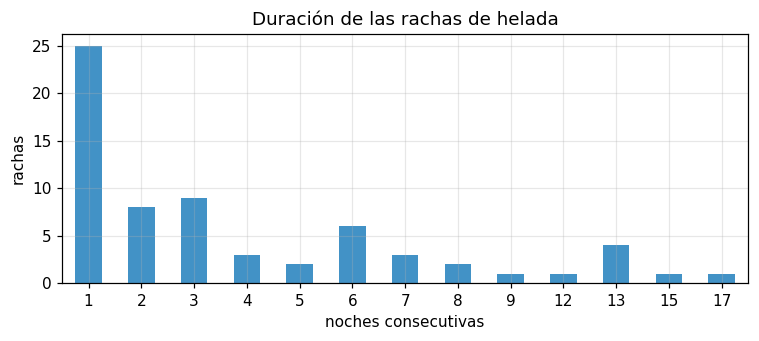

66 rachas; 33 de 3 o más noches; la más larga: 17 noches


,inicio,fin,noches,tmin,grados_hora
25,2023-06-30,2023-07-16,17,-3.6,140.3
52,2025-07-02,2025-07-16,15,-6.8,378.3
24,2023-06-16,2023-06-28,13,-4.5,187.6
7,2022-06-11,2022-06-23,13,-5.1,124.6
32,2024-05-29,2024-06-10,13,-5.2,167.5
8,2022-06-25,2022-07-07,13,-5.4,195.3
36,2024-07-09,2024-07-20,12,-5.0,181.8
22,2023-05-29,2023-06-06,9,-5.2,138.3
29,2023-08-14,2023-08-21,8,-2.4,24.8
15,2022-08-20,2022-08-27,8,-3.6,63.5


In [16]:
serie = N['helada'].reindex(pd.date_range(N.index.min(), N.index.max(), freq='D'))
grp = (serie != serie.shift()).cumsum()
R = []
for _, s in serie.groupby(grp):
    if s.iloc[0] is True or s.iloc[0] == True:
        R.append({'inicio': s.index[0], 'fin': s.index[-1], 'noches': len(s),
                  'tmin': N.loc[s.index, 'tmin'].min(), 'grados_hora': N.loc[s.index, 'grados_hora_bajo0'].sum()})
R = pd.DataFrame(R)
fig, ax = plt.subplots(figsize=(7, 3.2))
R['noches'].value_counts().sort_index().plot.bar(ax=ax, rot=0, color='#4292c6')
ax.set_xlabel('noches consecutivas'); ax.set_ylabel('rachas'); ax.set_title('Duración de las rachas de helada')
plt.tight_layout(); plt.show()
print(f"{len(R)} rachas; {(R.noches >= 3).sum()} de 3 o más noches; la más larga: {R.noches.max()} noches")
R.sort_values('noches', ascending=False).head(10).round({'tmin': 1, 'grados_hora': 1})

## 9. Tipo de helada según la humedad de hoja

Usamos el criterio de los notebooks anteriores. Si durante las horas bajo 0 °C la señal de la hoja (la mayor entre las caras arriba y bajo, relativa a la línea base seca de los 30 días previos) supera `UMB_HIELO`, el sensor detectó **escarcha** y la helada es **blanca**. Si no la supera, la helada es **negra**.

tipo
blanca    244
negra      24
Name: count, dtype: int64


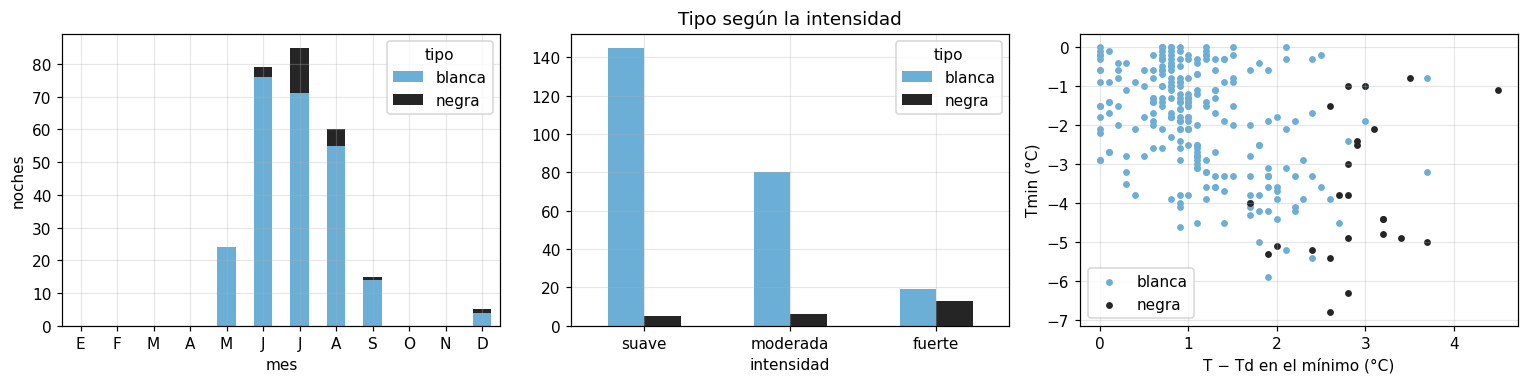

,tmin,horas_bajo0,grados_hora_bajo0,dep_tmin,td_tmin,hr_max,viento,nubosidad
tipo,,,,,,,,
blanca,-1.6,5.0,4.5,1.0,-1.8,93.0,0.5,13.7
negra,-4.2,8.0,22.3,2.8,-6.1,81.0,0.5,8.5


In [17]:
seco = D.index.hour.isin(range(11, 16)) & (D['pp'].fillna(0) == 0) & (D['HR'] < 60)
rel = {}
for k in ('arriba', 'bajo'):
    base = D[k].where(seco).rolling('30D', min_periods=20).median().shift(1).ffill()
    rel[k] = D[k] - base
D['hoja_rel'] = pd.concat(rel, axis=1).max(axis=1)
fh = D[D['es_noche'] & (D['Tmin'] <= 0)]
senal = fh.groupby('noche')['hoja_rel'].max()
N['senal_hoja'] = senal.reindex(N.index)
N['tipo'] = np.where(~N['helada'], np.nan,
                     np.where(N['senal_hoja'].isna(), 'sin dato', np.where(N['senal_hoja'] >= UMB_HIELO, 'blanca', 'negra')))
H = N[N['helada']]
print(H['tipo'].value_counts())
v = H[H.tipo.isin(['blanca', 'negra'])]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
pd.crosstab(v['mes'], v['tipo']).reindex(range(1, 13), fill_value=0).plot.bar(
    ax=axs[0], stacked=True, rot=0, color=[COL['blanca'], COL['negra']])
axs[0].set_xticks(range(12), MESES); axs[0].set_xlabel('mes'); axs[0].set_ylabel('noches')
pd.crosstab(v['intensidad'], v['tipo']).reindex(['suave', 'moderada', 'fuerte']).plot.bar(
    ax=axs[1], rot=0, color=[COL['blanca'], COL['negra']])
axs[1].set_title('Tipo según la intensidad')
for t in ['blanca', 'negra']:
    s = v[v.tipo == t]; axs[2].scatter(s['dep_tmin'], s['tmin'], s=12, color=COL[t], label=t)
axs[2].set_xlabel('T − Td en el mínimo (°C)'); axs[2].set_ylabel('Tmin (°C)'); axs[2].legend()
plt.tight_layout(); plt.show()
v.groupby('tipo')[['tmin', 'horas_bajo0', 'grados_hora_bajo0', 'dep_tmin', 'td_tmin', 'hr_max', 'viento',
                   *(['nubosidad'] if NUB is not None else [])]].median().round(1)

## 10. Heladas blancas y negras y la humedad del aire

La diferencia física entre los dos tipos de helada es el **vapor de agua del aire**:

* **Helada blanca**: el aire está húmedo. La superficie, enfriada por radiación, alcanza el **punto de escarcha** y el vapor se deposita como hielo. La deposición libera **calor latente** (~2,8 MJ/kg), que frena el enfriamiento. Además, el vapor de agua emite radiación infrarroja hacia el suelo (contrarradiación), lo que también limita la caída de temperatura.
* **Helada negra**: el aire es tan seco que la superficie **no llega al punto de escarcha** aunque baje de 0 °C. No se forma hielo visible, no hay calor latente y la contrarradiación es menor, así que la helada suele ser **más intensa y más larga**.

**Variables de humedad** (calculadas con la temperatura y el punto de rocío de la estación; no hace falta la presión):

| variable | definición |
|---|---|
| `HR` | humedad relativa respecto al agua líquida (%), medida |
| `Td` | punto de rocío (°C), medido |
| `e` | presión de vapor (hPa), a partir de Td con la ecuación de Magnus |
| `HRi` | humedad relativa **respecto al hielo** (%) = e / e_sat,hielo(T). La escarcha se deposita cuando la superficie llega a HRi = 100 % |
| `Tf` | **punto de escarcha** (°C): temperatura a la que el aire se satura respecto al hielo. Siempre es algo mayor que Td bajo 0 °C |
| `T − Tf` | depresión del punto de escarcha: cuánto debe enfriarse todavía el aire para que se forme escarcha |
| `ρv` | humedad absoluta (g/m³) |

> **Independencia de las medidas**: el tipo de helada se define con el **sensor de hoja**, y aquí lo relacionamos con la humedad medida por el **sensor de humedad del aire** a 2 m. Son instrumentos distintos, así que la relación no es circular.

In [18]:
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

def e_sat_agua(T):   # hPa (Magnus, sobre agua)
    return 6.112 * np.exp(17.62 * T / (243.12 + T))
def e_sat_hielo(T):  # hPa (Magnus, sobre hielo)
    return 6.112 * np.exp(22.46 * T / (272.62 + T))
def punto_escarcha(e):
    x = np.log(e / 6.112)
    return 272.62 * x / (22.46 - x)

D['e'] = e_sat_agua(D['Td'])
D['HRi'] = 100 * D['e'] / e_sat_hielo(D['T'])
D['Tf'] = punto_escarcha(D['e'])
D['dep_f'] = D['T'] - D['Tf']
D['rho_v'] = 216.7 * D['e'] / (D['T'] + 273.15)

# variables por noche
gN = D[D['es_noche']].groupby('noche')
for c, f in [('HRi', 'max'), ('HR', 'min'), ('e', 'mean'), ('rho_v', 'mean'), ('Td', 'min')]:
    N[f'{c}_{f}_noche'] = getattr(gN[c], f)().reindex(N.index)
for c in ('e', 'HRi', 'Tf', 'dep_f', 'rho_v'):
    N[f'{c}_tmin'] = D[c].reindex(N['hora_tmin']).values
for c in ('e', 'rho_v'):
    N[f'{c}_18h'] = D[c].reindex(N.index + pd.Timedelta(hours=18)).values
# humedad del día previo (12-16 h): ¿la masa de aire ya era seca por la tarde?
tarde = D[D.index.hour.isin(range(12, 17))]
N['Td_tarde'] = tarde.groupby(tarde.index.normalize())['Td'].mean().reindex(N.index)
N['HR_tarde'] = tarde.groupby(tarde.index.normalize())['HR'].mean().reindex(N.index)

HT = N[N['helada'] & N['tipo'].isin(['blanca', 'negra'])].copy()
HT['negra'] = HT['tipo'] == 'negra'
print(HT['tipo'].value_counts().to_dict())

{'blanca': 244, 'negra': 24}


### 10.1 La humedad del aire en las noches blancas y negras

Comparamos la humedad en tres momentos: la **tarde previa** (12–16 h), las **18 h** (momento en que podría emitirse un aviso) y la **hora de la temperatura mínima**. Para cada variable damos la mediana de cada tipo, la prueba de Mann-Whitney y el **AUC**: la probabilidad de que una noche negra tomada al azar sea "más seca" que una blanca tomada al azar (0,5 equivale al azar y 1 a una separación perfecta). El intervalo de confianza del 95 % del AUC se obtiene con un bootstrap por noche.

In [19]:
VARS_H = [
    ('HR_tarde', 'HR media 12–16 h (%)', 'tarde'), ('Td_tarde', 'Td medio 12–16 h (°C)', 'tarde'),
    ('HR_18h', 'HR 18 h (%)', '18 h'), ('Td_18h', 'Td 18 h (°C)', '18 h'), ('e_18h', 'e 18 h (hPa)', '18 h'),
    ('dep_18h', 'T − Td 18 h (°C)', '18 h'),
    ('HR_max_noche' if 'HR_max_noche' in N else 'hr_max', 'HR máx. noche (%)', 'noche'),
    ('HRi_max_noche', 'HRi máx. noche (%)', 'noche'), ('Td_min_noche', 'Td mín. noche (°C)', 'noche'),
    ('rho_v_mean_noche', 'ρv media noche (g/m³)', 'noche'),
    ('HRi_tmin', 'HRi en el mínimo (%)', 'mínimo'), ('Tf_tmin', 'punto de escarcha en el mínimo (°C)', 'mínimo'),
    ('dep_f_tmin', 'T − Tf en el mínimo (°C)', 'mínimo'), ('td_tmin', 'Td en el mínimo (°C)', 'mínimo'),
]
VARS_H = [v for v in VARS_H if v[0] in HT]

def auc_ic(y, x, n_boot=2000, seed=0):
    ok = ~np.isnan(x); y, x = y[ok], x[ok]
    a = roc_auc_score(y, x); signo = 1 if a >= 0.5 else -1
    r = np.random.default_rng(seed); bs = []
    for _ in range(n_boot):
        i = r.integers(0, len(y), len(y))
        if y[i].min() != y[i].max(): bs.append(roc_auc_score(y[i], signo * x[i]))
    return max(a, 1 - a), np.quantile(bs, [.025, .975]), signo

filas = []
for c, lab, mom in VARS_H:
    b, n_ = HT.loc[~HT.negra, c].dropna(), HT.loc[HT.negra, c].dropna()
    auc, ic, signo = auc_ic(HT['negra'].values, HT[c].values.astype(float))
    filas.append({'momento': mom, 'variable': lab, 'mediana blanca': b.median(), 'mediana negra': n_.median(),
                  'diferencia': n_.median() - b.median(), 'p Mann-Whitney': mannwhitneyu(b, n_).pvalue,
                  'AUC': auc, 'AUC IC95': f'[{ic[0]:.2f}, {ic[1]:.2f}]',
                  'negra si': 'mayor' if signo > 0 else 'menor'})
TAB_H = pd.DataFrame(filas)
TAB_H.to_csv(OUT / 'el_mantaro_tipo_helada_humedad.csv', index=False)
TAB_H.assign(**{'p Mann-Whitney': TAB_H['p Mann-Whitney'].map('{:.1e}'.format)}).round(
    {'mediana blanca': 1, 'mediana negra': 1, 'diferencia': 1, 'AUC': 2})

,momento,variable,mediana blanca,mediana negra,diferencia,p Mann-Whitney,AUC,AUC IC95,negra si
0,tarde,HR media 12–16 h (%),26.4,18.9,-7.5,3.9e-07,0.81,"[0.74, 0.88]",menor
1,tarde,Td medio 12–16 h (°C),-0.8,-5.4,-4.7,2.6e-07,0.82,"[0.74, 0.89]",menor
2,18 h,HR 18 h (%),35.0,23.0,-12.0,1.6e-09,0.87,"[0.80, 0.93]",menor
3,18 h,Td 18 h (°C),0.6,-5.2,-5.8,1.0e-09,0.88,"[0.81, 0.94]",menor
4,18 h,e 18 h (hPa),6.4,4.2,-2.2,1.0e-09,0.88,"[0.81, 0.94]",menor
5,18 h,T − Td 18 h (°C),15.5,21.4,5.9,2.9e-09,0.87,"[0.80, 0.93]",mayor
6,noche,HR máx. noche (%),93.0,81.0,-12.0,2.7e-14,0.97,"[0.94, 0.99]",menor
7,noche,HRi máx. noche (%),94.2,83.4,-10.8,1.5e-13,0.96,"[0.93, 0.98]",menor
8,noche,Td mín. noche (°C),-2.0,-7.4,-5.4,1.4e-11,0.92,"[0.87, 0.96]",menor
9,noche,ρv media noche (g/m³),4.8,3.3,-1.5,8.5e-12,0.92,"[0.86, 0.97]",menor


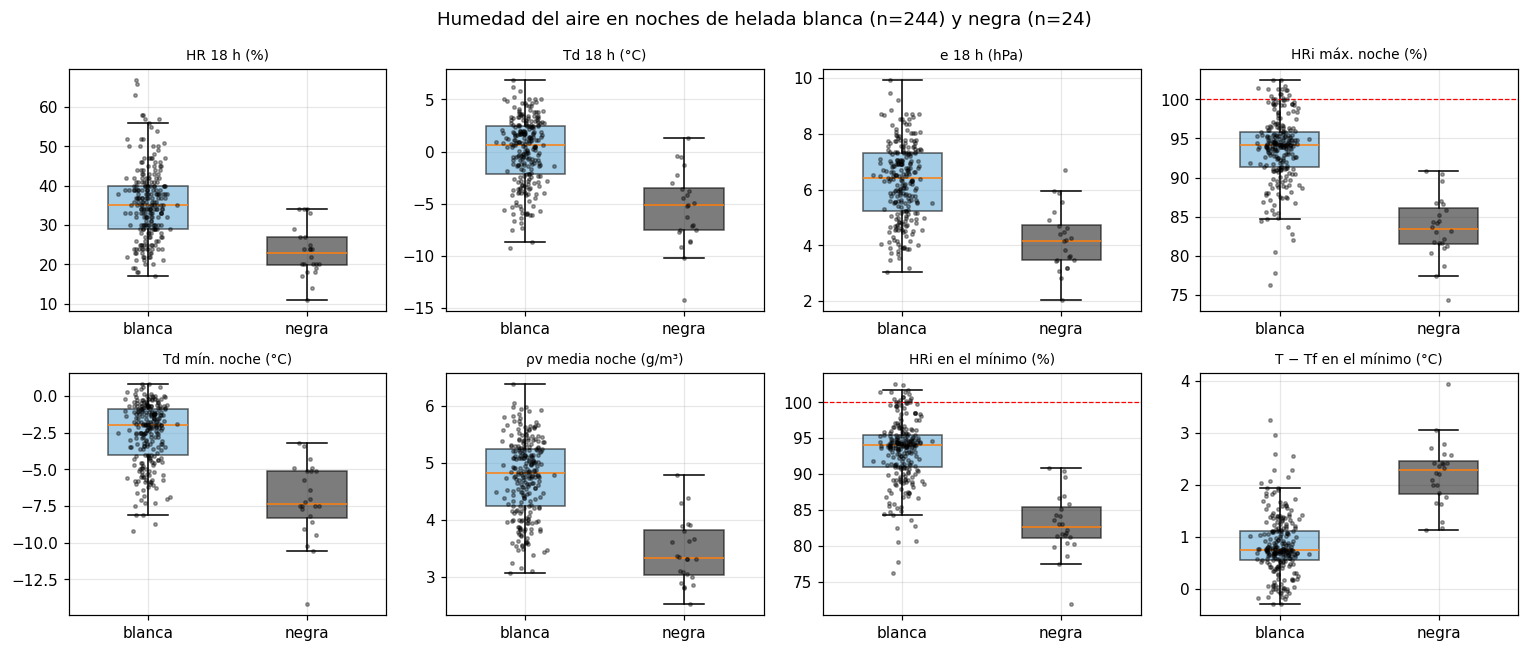

In [20]:
sel = [v for v in VARS_H if v[0] in ('HR_18h', 'Td_18h', 'e_18h', 'HRi_max_noche', 'HRi_tmin', 'dep_f_tmin', 'Td_min_noche', 'rho_v_mean_noche')]
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for ax, (c, lab, _) in zip(axs.flat, sel):
    datos = [HT.loc[~HT.negra, c].dropna(), HT.loc[HT.negra, c].dropna()]
    bp = ax.boxplot(datos, tick_labels=['blanca', 'negra'], patch_artist=True, widths=.5, showfliers=False)
    for p, col in zip(bp['boxes'], [COL['blanca'], COL['negra']]): p.set_facecolor(col); p.set_alpha(.6)
    for k, d_ in enumerate(datos):
        ax.scatter(np.random.default_rng(k).normal(k + 1, .06, len(d_)), d_, s=5, color='k', alpha=.35, zorder=3)
    ax.set_title(lab, fontsize=9)
    if 'HRi' in c: ax.axhline(100, color='r', ls='--', lw=.8)
plt.suptitle(f'Humedad del aire en noches de helada blanca (n={(~HT.negra).sum()}) y negra (n={HT.negra.sum()})')
plt.tight_layout(); plt.show()

### 10.2 Evolución de la humedad durante la noche

Curvas medianas de las noches blancas y negras, de 12 h a 10 h del día siguiente. La línea roja de 100 % en HRi marca la saturación respecto al hielo **a 2 m**. La superficie de la hoja está más fría, así que alcanza su propia saturación antes que el aire del abrigo.

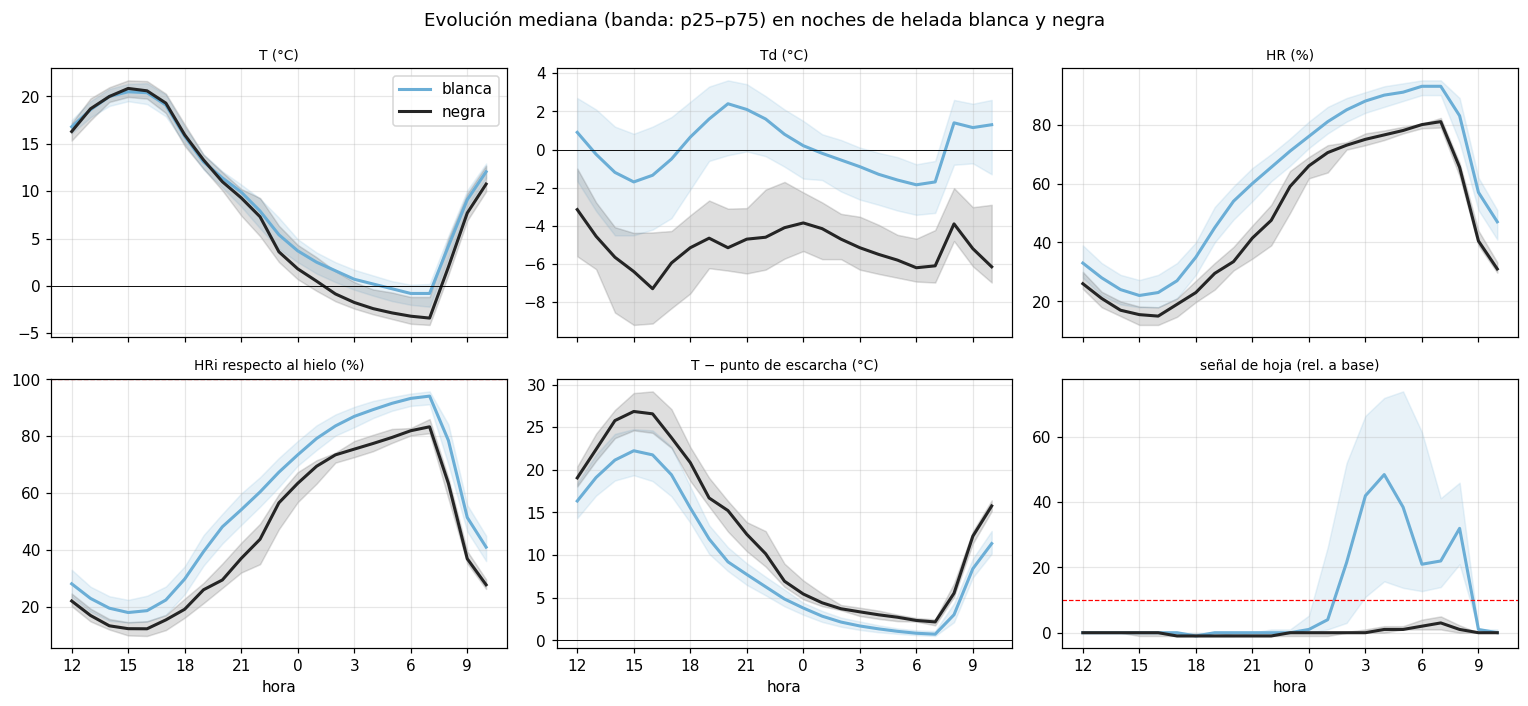

In [21]:
horas = pd.timedelta_range('12h', '34h', freq='h')
def curvas(noches, col):
    M = np.vstack([D[col].reindex(n_ + horas).values for n_ in noches])
    return np.nanmedian(M, axis=0), np.nanpercentile(M, 25, axis=0), np.nanpercentile(M, 75, axis=0)
fig, axs = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
xs = np.arange(12, 35)
for ax, (col, lab) in zip(axs.flat, [('T', 'T (°C)'), ('Td', 'Td (°C)'), ('HR', 'HR (%)'),
                                     ('HRi', 'HRi respecto al hielo (%)'), ('dep_f', 'T − punto de escarcha (°C)'),
                                     ('hoja_rel', 'señal de hoja (rel. a base)')]):
    for t in ['blanca', 'negra']:
        med, q1, q3 = curvas(HT.index[HT.tipo == t], col)
        ax.plot(xs, med, color=COL[t], lw=2, label=f'{t}')
        ax.fill_between(xs, q1, q3, color=COL[t], alpha=.15)
    if col in ('T', 'Td', 'dep_f'): ax.axhline(0, color='k', lw=.6)
    if col == 'HRi': ax.axhline(100, color='r', ls='--', lw=.8)
    if col == 'hoja_rel': ax.axhline(UMB_HIELO, color='r', ls='--', lw=.8)
    ax.set_title(lab, fontsize=9)
for ax in axs[-1]:
    ax.set_xticks(range(12, 35, 3), [h % 24 for h in range(12, 35, 3)]); ax.set_xlabel('hora')
axs[0, 0].legend(); plt.suptitle('Evolución mediana (banda: p25–p75) en noches de helada blanca y negra')
plt.tight_layout(); plt.show()

### 10.3 ¿A partir de qué humedad del aire aparece la escarcha en la hoja?

Para **cada hora con helada** (Tmin ≤ 0 °C) relacionamos la HRi y la depresión del punto de escarcha medidas a 2 m con la señal del sensor de hoja. La HRi a la que la señal empieza a subir indica cuánto más fría que el aire está la superficie.

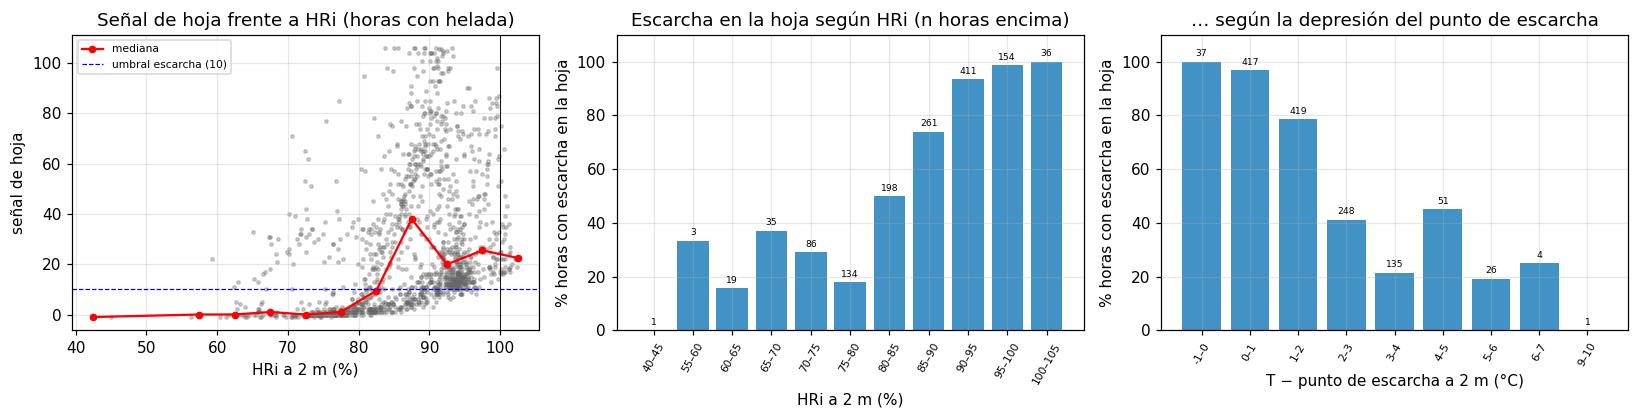

La hoja tiene escarcha en ≥50 % de las horas a partir de HRi(2 m) ≈ 80–85 %


señal  p_escarcha  horas
por HRi  (40.0, 45.0]     -1.0        0.00      1
         (55.0, 60.0]      0.0        0.33      3
         (60.0, 65.0]      0.0        0.16     19
         (65.0, 70.0]      1.0        0.37     35
         (70.0, 75.0]      0.0        0.29     86
         (75.0, 80.0]      1.0        0.18    134
         (80.0, 85.0]      9.5        0.50    198
         (85.0, 90.0]     38.0        0.74    261
         (90.0, 95.0]     20.0        0.93    411
         (95.0, 100.0]    25.5        0.99    154
         (100.0, 105.0]   22.5        1.00     36
por T−Tf (-1.0, 0.0]      23.0        1.00     37
         (0.0, 1.0]       20.0        0.97    417
         (1.0, 2.0]       37.0        0.79    419
         (2.0, 3.0]        5.0        0.41    248
         (3.0, 4.0]        1.0        0.21    135
         (4.0, 5.0]        2.0        0.45     51
         (5.0, 6.0]        0.5        0.19     26
         (6.0, 7.0]       -0.5        0.25      4
         (9.0, 10.0]      -1.0        0.00      1

In [22]:
hh = D[D['es_noche'] & (D['Tmin'] <= 0)].dropna(subset=['HRi', 'hoja_rel']).copy()
hh['escarcha'] = hh['hoja_rel'] >= UMB_HIELO
b_hri = np.arange(40, 111, 5)
g1 = hh.groupby(pd.cut(hh['HRi'], b_hri), observed=True).agg(señal=('hoja_rel', 'median'), p_escarcha=('escarcha', 'mean'), horas=('escarcha', 'size'))
b_dep = np.arange(-1, 10.5, 1)
g2 = hh.groupby(pd.cut(hh['dep_f'], b_dep), observed=True).agg(señal=('hoja_rel', 'median'), p_escarcha=('escarcha', 'mean'), horas=('escarcha', 'size'))
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
axs[0].scatter(hh['HRi'], hh['hoja_rel'].clip(-5, 110), s=5, alpha=.3, color='0.4')
axs[0].plot([i.mid for i in g1.index], g1['señal'], 'r-o', ms=4, label='mediana')
axs[0].axhline(UMB_HIELO, color='b', ls='--', lw=.8, label=f'umbral escarcha ({UMB_HIELO})')
axs[0].axvline(100, color='k', lw=.6); axs[0].set_xlabel('HRi a 2 m (%)'); axs[0].set_ylabel('señal de hoja')
axs[0].legend(fontsize=7); axs[0].set_title('Señal de hoja frente a HRi (horas con helada)')
for ax, g, lab in [(axs[1], g1, 'HRi a 2 m (%)'), (axs[2], g2, 'T − punto de escarcha a 2 m (°C)')]:
    ax.bar(range(len(g)), g['p_escarcha'] * 100, color='#4292c6')
    for i, (p, nn) in enumerate(zip(g['p_escarcha'], g['horas'])): ax.text(i, p * 100 + 2, int(nn), ha='center', fontsize=6)
    ax.set_xticks(range(len(g)), [f'{i.left:g}–{i.right:g}' for i in g.index], rotation=60, fontsize=7)
    ax.set_xlabel(lab); ax.set_ylabel('% horas con escarcha en la hoja'); ax.set_ylim(0, 110)
axs[1].set_title('Escarcha en la hoja según HRi (n horas encima)'); axs[2].set_title('… según la depresión del punto de escarcha')
plt.tight_layout(); plt.show()
# HRi a la que la mitad de las horas ya tiene escarcha
p50 = g1[g1['p_escarcha'] >= 0.5].index.min()
print(f'La hoja tiene escarcha en ≥50 % de las horas a partir de HRi(2 m) ≈ {p50.left:g}–{p50.right:g} %')
pd.concat({'por HRi': g1, 'por T−Tf': g2}).round(2)

### 10.4 Probabilidad de helada negra según la humedad de la tarde

Si va a helar, ¿qué probabilidad hay de que la helada sea **negra**, según la humedad medida a las 18 h? Ajustamos una **regresión logística de una sola variable** (Td a las 18 h), que sirve como regla práctica para un aviso vespertino.

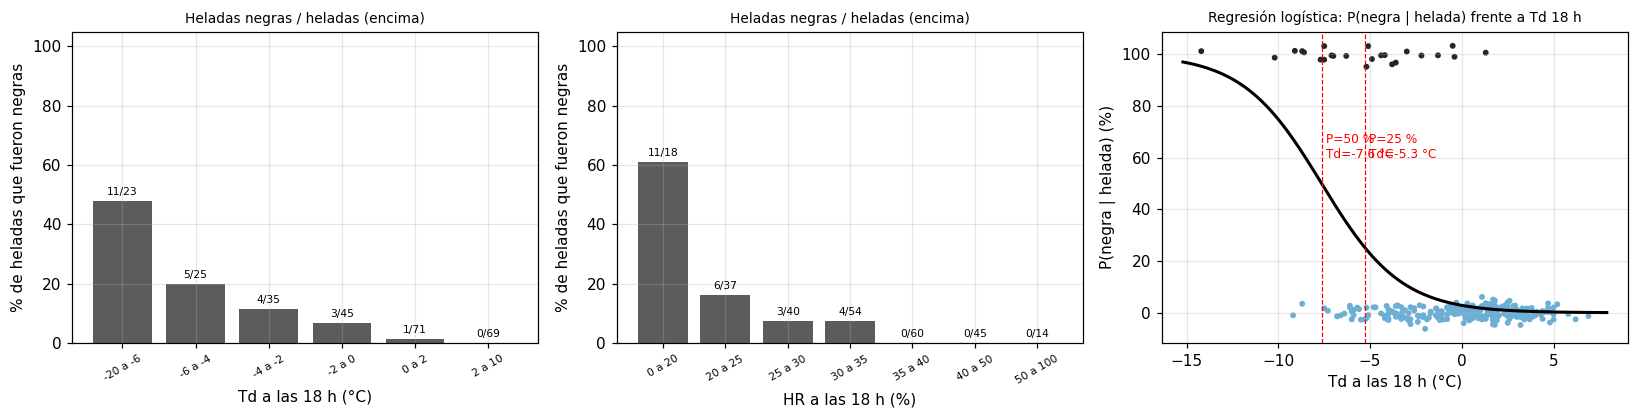

Si hiela: P(negra) = 50 % con Td(18 h) ≈ -7.6 °C, 25 % con Td(18 h) ≈ -5.3 °C


In [23]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
# frecuencia por clases
for ax, (c, bins, lab) in zip(axs[:2], [('Td_18h', [-20, -6, -4, -2, 0, 2, 10], 'Td a las 18 h (°C)'),
                                        ('HR_18h', [0, 20, 25, 30, 35, 40, 50, 100], 'HR a las 18 h (%)')]):
    g = HT.groupby(pd.cut(HT[c], bins), observed=True)['negra'].agg(['mean', 'sum', 'size'])
    ax.bar(range(len(g)), g['mean'] * 100, color=COL['negra'], alpha=.75)
    for i, (m, s, nn) in enumerate(g.values): ax.text(i, m * 100 + 2, f'{int(s)}/{int(nn)}', ha='center', fontsize=7)
    ax.set_xticks(range(len(g)), [f'{i.left:g} a {i.right:g}' for i in g.index], rotation=30, fontsize=7)
    ax.set_xlabel(lab); ax.set_ylabel('% de heladas que fueron negras'); ax.set_ylim(0, 105)
    ax.set_title('Heladas negras / heladas (encima)', fontsize=9)
# logística con Td 18 h
ok = HT['Td_18h'].notna()
lr = LogisticRegression().fit(HT.loc[ok, ['Td_18h']], HT.loc[ok, 'negra'])
xs = np.linspace(HT['Td_18h'].min() - 1, HT['Td_18h'].max() + 1, 200)
ps = lr.predict_proba(pd.DataFrame({'Td_18h': xs}))[:, 1]
td50 = -lr.intercept_[0] / lr.coef_[0, 0]
td25 = (np.log(.25 / .75) - lr.intercept_[0]) / lr.coef_[0, 0]
axs[2].plot(xs, ps * 100, 'k-', lw=2)
axs[2].scatter(HT['Td_18h'], HT['negra'] * 100 + np.random.default_rng(0).normal(0, 2, len(HT)), s=8,
               c=np.where(HT['negra'], COL['negra'], COL['blanca']))
for v, txt in [(td50, '50 %'), (td25, '25 %')]:
    axs[2].axvline(v, color='r', ls='--', lw=.8); axs[2].text(v, 60, f' P={txt}\n Td={v:.1f} °C', fontsize=8, color='r')
axs[2].set_xlabel('Td a las 18 h (°C)'); axs[2].set_ylabel('P(negra | helada) (%)')
axs[2].set_title('Regresión logística: P(negra | helada) frente a Td 18 h', fontsize=9)
plt.tight_layout(); plt.show()
print(f'Si hiela: P(negra) = 50 % con Td(18 h) ≈ {td50:.1f} °C, 25 % con Td(18 h) ≈ {td25:.1f} °C')

### 10.5 Humedad del aire e intensidad de la helada

El aire seco favorece heladas más fuertes: hay menos contrarradiación del vapor y no hay calor latente. Lo comprobamos con la relación entre el punto de rocío de la tarde y la Tmin de las noches con helada.

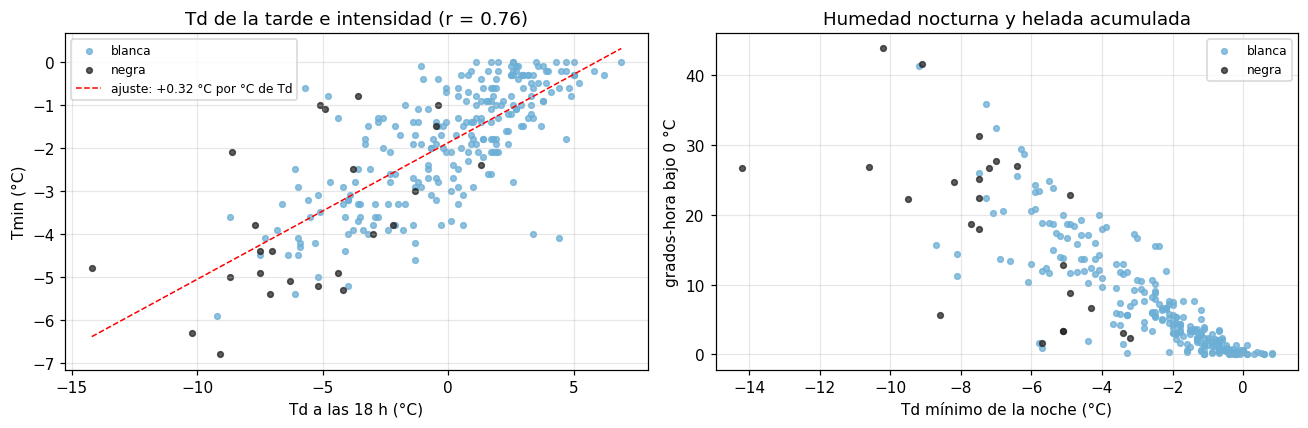

median         size      
tipo       blanca negra blanca negra
clase_Td18                          
(-20, -6]    -4.1  -4.9     12    11
(-6, -3]     -3.3  -3.2     35     8
(-3, 0]      -2.0  -2.2     58     4
(0, 3]       -1.2  -2.4    100     1
(3, 10]      -0.5   NaN     39     0

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for t in ['blanca', 'negra']:
    s = HT[HT.tipo == t]
    axs[0].scatter(s['Td_18h'], s['tmin'], s=14, color=COL[t], label=t, alpha=.75)
    axs[1].scatter(s['Td_min_noche'], s['grados_hora_bajo0'], s=14, color=COL[t], label=t, alpha=.75)
ok = HT[['Td_18h', 'tmin']].dropna()
pend, ord_ = np.polyfit(ok['Td_18h'], ok['tmin'], 1)
xx = np.linspace(ok['Td_18h'].min(), ok['Td_18h'].max(), 10)
axs[0].plot(xx, pend * xx + ord_, 'r--', lw=1, label=f'ajuste: {pend:+.2f} °C por °C de Td')
axs[0].set_xlabel('Td a las 18 h (°C)'); axs[0].set_ylabel('Tmin (°C)'); axs[0].legend(fontsize=8)
axs[0].set_title(f"Td de la tarde e intensidad (r = {ok.corr().iloc[0, 1]:.2f})")
axs[1].set_xlabel('Td mínimo de la noche (°C)'); axs[1].set_ylabel('grados-hora bajo 0 °C')
axs[1].set_title('Humedad nocturna y helada acumulada'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
# ¿la diferencia de intensidad se explica solo por la humedad? Tmin por clases de Td, separando por tipo
HT['clase_Td18'] = pd.cut(HT['Td_18h'], [-20, -6, -3, 0, 3, 10])
HT.pivot_table(index='clase_Td18', columns='tipo', values='tmin', aggfunc=['median', 'size'], observed=False).round(1)

### 10.6 Estacionalidad de la humedad y del tipo de helada

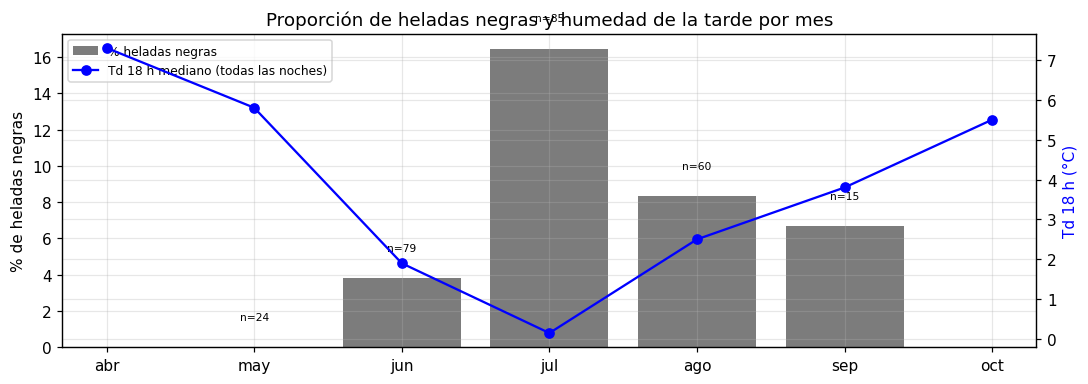

In [25]:
fig, ax = plt.subplots(figsize=(10, 3.6))
m_ = range(4, 11)
td_mes = N[N.mes.isin(m_)].groupby('mes')['Td_18h'].median()
hri_mes = N[N.mes.isin(m_) & N.helada].groupby('mes')['HRi_max_noche'].median()
frac_negra = HT.groupby('mes')['negra'].mean().reindex(m_) * 100
n_hel = HT.groupby('mes').size().reindex(m_, fill_value=0)
ax.bar([m - 1 for m in m_], frac_negra.values, color=COL['negra'], alpha=.6, label='% heladas negras')
for m, v, nn in zip(m_, frac_negra.values, n_hel.values):
    if nn: ax.text(m - 1, (0 if np.isnan(v) else v) + 1.5, f'n={nn}', ha='center', fontsize=7)
ax.set_ylabel('% de heladas negras'); ax.set_xticks([m - 1 for m in m_], [MESES_L[m - 1] for m in m_])
ax2 = ax.twinx(); ax2.plot([m - 1 for m in td_mes.index], td_mes.values, 'b-o', label='Td 18 h mediano (todas las noches)')
ax2.set_ylabel('Td 18 h (°C)', color='b'); ax.set_title('Proporción de heladas negras y humedad de la tarde por mes')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

In [26]:
# Resumen de la sección
r_td = TAB_H.set_index('variable').loc['Td 18 h (°C)']
mejor = TAB_H.sort_values('AUC', ascending=False).iloc[0]
print('Resumen — tipo de helada y humedad del aire')
print(f"  Noches: {(~HT.negra).sum()} blancas, {HT.negra.sum()} negras")
print(f"  Td 18 h mediano: blanca {r_td['mediana blanca']:.1f} °C, negra {r_td['mediana negra']:.1f} °C (AUC {r_td['AUC']:.2f})")
print(f"  Variable que mejor separa los tipos: {mejor['variable']} (AUC {mejor['AUC']:.2f} {mejor['AUC IC95']})")
print(f"  Escarcha en la hoja en ≥50 % de las horas desde HRi(2 m) ≈ {p50.left:g}–{p50.right:g} %")
print(f"  P(negra | helada) = 50 % con Td 18 h ≈ {td50:.1f} °C")

Resumen — tipo de helada y humedad del aire
  Noches: 244 blancas, 24 negras
  Td 18 h mediano: blanca 0.6 °C, negra -5.2 °C (AUC 0.88)
  Variable que mejor separa los tipos: HR máx. noche (%) (AUC 0.97 [0.94, 0.99])
  Escarcha en la hoja en ≥50 % de las horas desde HRi(2 m) ≈ 80–85 %
  P(negra | helada) = 50 % con Td 18 h ≈ -7.6 °C


**Advertencias de la sección**

* Hay solo **24 noches negras**. Los intervalos de los AUC y la curva logística son amplios; conviene recalcularlos con cada temporada nueva.
* La HRi y el punto de escarcha se calculan con la temperatura y el punto de rocío **a 2 m**. En la superficie de la hoja, más fría, la saturación llega antes, y por eso aparece escarcha con HRi del aire por debajo de 100 %.
* La HR de los sensores capacitivos pierde precisión con aire muy frío y muy seco (errores típicos de ±2–3 %, mayores por debajo del 20 %). El **punto de rocío y la HRi en las noches más secas** son menos fiables.
* La clasificación blanca/negra depende del umbral `UMB_HIELO` del sensor de hoja (ver sección 9).

## 11. Temperatura del suelo durante las heladas

El suelo almacena calor durante el día y lo cede de noche. Comparamos el aire a 2 m con el suelo a 5 cm y a 15 cm en la hora del mínimo.

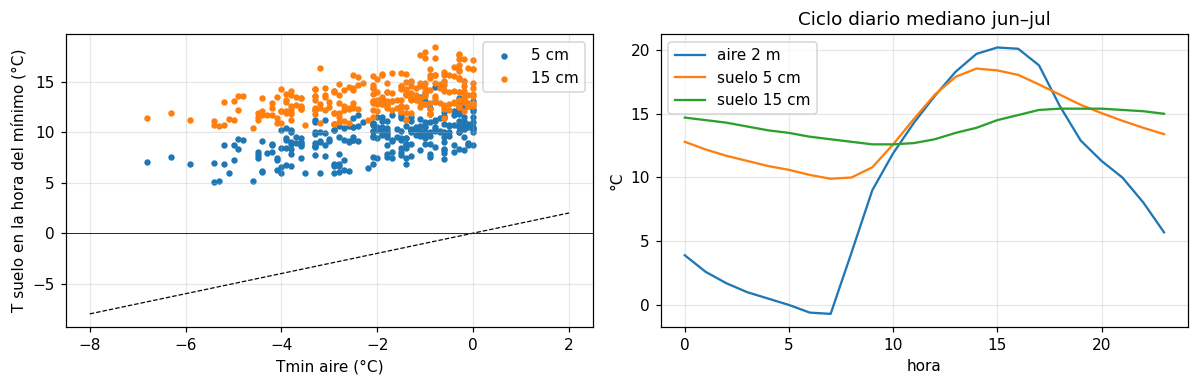

Noches de helada con suelo a 5 cm ≤ 0 °C: 0%


,tmin_aire,suelo5,suelo15
count,268.0,268.0,268.0
mean,-2.0,9.5,13.5
std,1.5,1.8,1.6
min,-6.8,5.1,10.4
25%,-3.1,8.4,12.4
50%,-1.8,9.6,13.2
75%,-0.8,10.6,14.4
max,0.0,14.5,18.4


In [27]:
S = pd.DataFrame({'tmin_aire': H['tmin'],
                  'suelo5': D['Tsuelo5'].reindex(H['hora_tmin']).values,
                  'suelo15': D['Tsuelo15'].reindex(H['hora_tmin']).values}, index=H.index).dropna()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].scatter(S['tmin_aire'], S['suelo5'], s=10, label='5 cm'); axs[0].scatter(S['tmin_aire'], S['suelo15'], s=10, label='15 cm')
axs[0].plot([-8, 2], [-8, 2], 'k--', lw=.8); axs[0].axhline(0, color='b', lw=.6)
axs[0].set_xlabel('Tmin aire (°C)'); axs[0].set_ylabel('T suelo en la hora del mínimo (°C)'); axs[0].legend()
mes_s = H.groupby('mes').size().index
c = D.loc[D.index.month.isin([6, 7])]
cyc = c.groupby(c.index.hour)[['T', 'Tsuelo5', 'Tsuelo15']].median()
axs[1].plot(cyc.index, cyc['T'], label='aire 2 m'); axs[1].plot(cyc.index, cyc['Tsuelo5'], label='suelo 5 cm')
axs[1].plot(cyc.index, cyc['Tsuelo15'], label='suelo 15 cm'); axs[1].set_xlabel('hora'); axs[1].set_ylabel('°C')
axs[1].set_title('Ciclo diario mediano jun–jul'); axs[1].legend()
plt.tight_layout(); plt.show()
print(f"Noches de helada con suelo a 5 cm ≤ 0 °C: {(S['suelo5'] <= 0).mean():.0%}")
S.describe().round(1)

## 12. Riesgo agronómico

Umbrales orientativos de daño por frío para los cultivos del valle:

| cultivo | daño aproximado (temperatura del tejido) |
|---|---|
| papa (*S. tuberosum*), haba, arveja en floración | −1 a −2 °C |
| maíz amiláceo (plántula/floración) | −1 a −2 °C |
| alcachofa | −2 a −3 °C |
| cereales de grano pequeño, papas nativas amargas | −3 a −5 °C |

Como el cultivo puede estar **2–3 °C más frío que el aire a 2 m** en noches despejadas, un valor de **2 °C en el abrigo** ya puede significar 0 °C en la hoja.

Indicadores:

* probabilidad mensual de que la Tmin no supere cada umbral;
* **grados-hora bajo 0 °C**, la suma de (0 − T) en las horas de helada, que resume intensidad y duración a la vez;
* noches con **más de 4 h bajo −2 °C**.

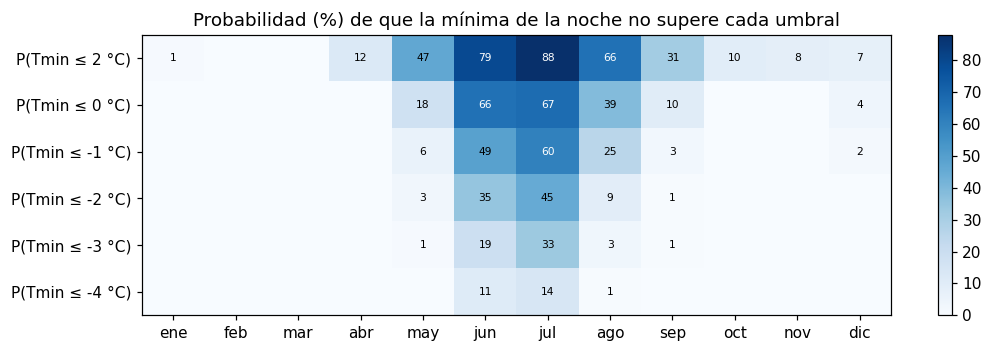

,P(Tmin ≤ 2 °C),P(Tmin ≤ 0 °C),P(Tmin ≤ -1 °C),P(Tmin ≤ -2 °C),P(Tmin ≤ -3 °C),P(Tmin ≤ -4 °C),grados-hora bajo 0 (media/mes),noches >4 h bajo −2 °C (media/mes)
ene,0.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
feb,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mar,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
abr,12.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
may,46.7,17.8,5.9,3.0,0.7,0.0,14.4,0.0
jun,79.2,65.8,49.2,35.0,19.2,10.8,192.8,4.2
jul,88.1,67.5,60.3,45.2,33.3,14.3,219.5,5.0
ago,65.8,38.7,25.2,9.0,3.2,0.6,49.6,0.0
sep,31.3,10.0,2.7,0.7,0.7,0.0,7.2,0.0
oct,9.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
riesgo = pd.DataFrame({f'P(Tmin ≤ {u} °C)': N.groupby('mes')['tmin'].apply(lambda s: (s <= u).mean() * 100)
                       for u in [2, 0, -1, -2, -3, -4]})
riesgo['grados-hora bajo 0 (media/mes)'] = N.groupby(['anio', 'mes'])['grados_hora_bajo0'].sum().groupby('mes').mean()
riesgo['noches >4 h bajo −2 °C (media/mes)'] = (N.assign(x=N['horas_bajo_m2'] > 4)
                                                .groupby(['anio', 'mes'])['x'].sum().groupby('mes').mean())
riesgo.index = [MESES_L[m - 1] for m in riesgo.index]
fig, ax = plt.subplots(figsize=(10, 3.3))
r = riesgo.iloc[:, :6].T
im = ax.imshow(r.values, cmap='Blues', aspect='auto'); ax.grid(False)
ax.set_xticks(range(r.shape[1]), r.columns); ax.set_yticks(range(r.shape[0]), r.index)
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        if r.values[i, j] >= 0.5: ax.text(j, i, f'{r.values[i, j]:.0f}', ha='center', va='center', fontsize=7,
                                         color='w' if r.values[i, j] > 50 else 'k')
ax.set_title('Probabilidad (%) de que la mínima de la noche no supere cada umbral'); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
riesgo.round(1)

In [29]:
# Riesgo para la siembra: probabilidad de al menos una helada (≤ 0 °C y ≤ −2 °C) después de cada fecha
# (en las temporadas completas)
filas = []
for f in pd.date_range('2025-08-01', '2025-12-31', freq='15D'):
    r = {'fecha': f.strftime('%d-%b')}
    for u in (0, -2):
        hay = [((N.anio == a) & (N['tmin'] <= u) & (N.index.dayofyear >= f.dayofyear)).any() for a in COMPLETAS]
        r[f'% años con helada ≤{u} °C después'] = 100 * np.mean(hay)
    filas.append(r)
print('Temporadas completas usadas:', COMPLETAS)
pd.DataFrame(filas).set_index('fecha')

Temporadas completas usadas: [2023, 2024, 2025]


,% años con helada ≤0 °C después,% años con helada ≤-2 °C después
fecha,,
01-Aug,100.000000,100.0
16-Aug,100.000000,100.0
31-Aug,100.000000,0.0
15-Sep,66.666667,0.0
30-Sep,33.333333,0.0
15-Oct,33.333333,0.0
30-Oct,33.333333,0.0
14-Nov,33.333333,0.0
29-Nov,33.333333,0.0


## 13. Resumen

In [30]:
c0 = TEMP0[TEMP0.completa]
resumen = {
    'Periodo con datos': f"{D['Tmin'].first_valid_index():%Y-%m-%d} a {D['Tmin'].last_valid_index():%Y-%m-%d}",
    'Temporadas completas': ', '.join(map(str, COMPLETAS)),
    'Noches válidas': len(N),
    'Noches con helada ≤0 °C': int(N['helada'].sum()),
    'Noches con helada ≤2 °C': int(N['helada_agro'].sum()),
    'Heladas por temporada completa (media)': round(anual.loc[anual.completa, 'heladas'].mean(), 1),
    'Tmin absoluta': f"{N['tmin'].min():.1f} °C ({N['tmin'].idxmin():%Y-%m-%d})",
    'Mes con más heladas': MESES_L[int(mens['helada'].idxmax()) - 1] + f" ({mens['helada'].max() * 100:.0f} % de las noches)",
    'Primera helada (mediana, ≤0 °C)': fecha_doy(c0['primera'].dt.dayofyear.median()) if len(c0) else '—',
    'Última helada (mediana, ≤0 °C)': fecha_doy(c0['última'].dt.dayofyear.median()) if len(c0) else '—',
    'Heladas fuera de may–sep': f"{len(FUERA)} noches (máx. {FUERA['tmin'].min():.1f} °C)" if len(FUERA) else '0',
    'Hora mediana del mínimo': f"{EV['h_tmin'].median():.0f}:00",
    'Duración mediana bajo 0 °C': f"{EV['duracion'].median():.0f} h",
    'Racha más larga': f"{R['noches'].max()} noches",
    'Heladas blancas / negras (hoja)': f"{(H.tipo == 'blanca').sum()} / {(H.tipo == 'negra').sum()}",
    'Td 18 h mediano (blanca / negra)': f"{r_td['mediana blanca']:.1f} / {r_td['mediana negra']:.1f} °C",
    'P(negra | helada) = 50 % con Td 18 h ≈': f"{td50:.1f} °C",
    'Escarcha en la hoja desde HRi(2 m) ≈': f"{p50.left:g}–{p50.right:g} %",
}
N.reset_index().to_csv(OUT / 'el_mantaro_noches.csv', index=False)
print('Tabla de noches ->', OUT / 'el_mantaro_noches.csv')
pd.Series(resumen, name='J2 El Mantaro').to_frame()

Tabla de noches -> /home/luismartin/Documentos/agro/E3/proy1/resultados/el_mantaro_noches.csv


,J2 El Mantaro
Periodo con datos,2022-03-18 a 2026-10-23
Temporadas completas,"2023, 2024, 2025"
Noches válidas,1560
Noches con helada ≤0 °C,268
Noches con helada ≤2 °C,467
Heladas por temporada completa (media),59.7
Tmin absoluta,-6.8 °C (2025-07-05)
Mes con más heladas,jul (67 % de las noches)
"Primera helada (mediana, ≤0 °C)",23-May
"Última helada (mediana, ≤0 °C)",23-Sep
